# Exercise 4.2 | Categorical Predictors

Do individuals in households earning under $35,000 report more poor mental health days? We'll use the 2011 Behavioral Risk Factor Surveillance System (BRFSS) data to fit a bivariate GLM with a binary predictor.

The outcome is **MENTHLTH**, the number of days in the past 30 days when mental health was not good. The predictor is **low_income**: 1 for annual household income below $35,000, and 0 for $35,000 or more. Complete the notebook, then enter your answers in Gradescope.

In [1]:
# Imports
import pandas as pd
import statsmodels.formula.api as smf
import seaborn as sns
import matplotlib.pyplot as plt

# File Path
file_path = 'https://econ-0150.tayweid.io/data/' 

The cleaned dataset uses income categories 1–8. Categories 1–5 represent household income below $35,000; categories 6–8 represent $35,000 or more. Drop missing income and mental-health responses **before** creating the indicator so that missing income is not classified as higher income.

For this exercise, we fit an unweighted model to these observations. We do not use the BRFSS survey weights or survey design to estimate population-wide effects.

In [2]:
# Load BRFSS data and keep complete responses
data = pd.read_csv(file_path + 'BRFSS_cleaned.csv')
data = data[['INCOME2', 'MENTHLTH']].dropna().copy()

# Create binary indicator: household income below $35,000
data['low_income'] = (data['INCOME2'] <= 5).astype(int)
data.head()

,INCOME2,MENTHLTH,low_income
0,8.0,0.0,0
1,7.0,0.0,0
2,6.0,0.0,0
3,4.0,5.0,1
4,1.0,0.0,1


## Explore the Data

**Question 1.** Make a box plot of `MENTHLTH` for each income group. Which group appears to report more poor mental health days? Describe the shape of the distributions.

*Hint: `sns.boxplot(data=data, x='low_income', y='MENTHLTH')`. Remember that 0 is $35,000 or more and 1 is below $35,000.*

<Axes: xlabel='low_income', ylabel='MENTHLTH'>

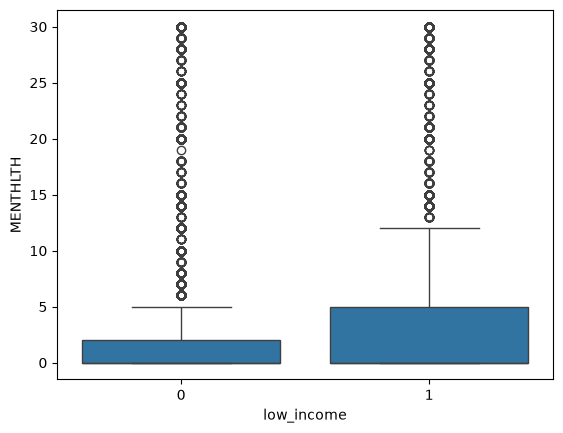

In [3]:
sns.boxplot(data=data, x='low_income', y='MENTHLTH')

{++The below \$35,000 group (1) appears to report more poor mental health days. Both distributions are right-skewed: most respondents report 0 days, with a long tail up to 30.++}

**Question 2.** Calculate the number of observations and the mean of `MENTHLTH` in each group. What is the difference in means (below $35,000 minus $35,000 or more)?

*Hint: `data.groupby('low_income')['MENTHLTH'].agg(['count', 'mean'])`.*

In [4]:
# Group sizes and means
means = data.groupby('low_income')['MENTHLTH'].agg(['count', 'mean'])
print(means)

# Difference in means
print(means['mean'][1] - means['mean'][0])

             count      mean
low_income                  
0           127450  2.427870
1            79289  5.087137
2.659267176616328


## Fitting the Model

We fit the bivariate GLM:

$$MentalHealthDays_i = \beta_0 + \beta_1 \cdot LowIncome_i + \epsilon_i$$

When the predictor is binary, the fitted values are the two group means. The reference group (`low_income = 0`) is households earning $35,000 or more.

**Question 3.** Fit the model and print the coefficient table.

*Hint: save `smf.ols('MENTHLTH ~ low_income', data=data).fit()` as `model`, then use `print(model.summary().tables[1])`.*

In [5]:
# Model: y = b + mx
model = smf.ols('MENTHLTH ~ low_income', data=data).fit() # Intercept is included by default
print(model.summary().tables[1])

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.4279      0.021    114.903      0.000       2.386       2.469
low_income     2.6593      0.034     77.941      0.000       2.592       2.726


**Question 4.** Report the estimated intercept ($\hat{\beta}_0$) and slope ($\hat{\beta}_1$). Compare the intercept to the reference-group mean and the slope to the difference in means from Question 2. What do you notice?

{++The estimated intercept is 2.428 and the estimated slope is 2.659. The intercept equals the reference-group mean, and the slope++} is the difference in group means.

## Predictions

**Question 5.** Use the estimated coefficients to predict poor mental health days for each income group. How do these predictions compare with the group means?

*Hint: use `model.params['Intercept']` for the reference group and add `model.params['low_income']` for the lower-income group.*

In [6]:
# Parameters
b0 = model.params['Intercept']
b1 = model.params['low_income']

# Predict: $35,000 or more
print(b0)

# Predict: Below $35,000
print(b0 + b1)

2.4278697528450586
5.087136929459485


{++The predictions are 2.428 days for the \$35,000 or more group and 5.087 days for the below \$35,000 group. They equal the group means.++}

## Interpretation

**Question 6.** What is the p-value on `low_income`? State the null hypothesis in terms of the two population means. Would you reject it at the 5% significance level under this model's assumptions?

{++The p-value on `low_income` is 0.000.++} $H_0: \beta_1 = 0$. {++Respondents below \$35,000 and at \$35,000 or more++} have the same average {++number of poor mental health days. Yes.++} We reject the null hypothesis{++ at the 5% significance level.++}

**Question 7.** Interpret the intercept and slope in context, including the units (days out of the past 30 days). Does this observational comparison establish that lower income causes worse mental health? Explain.

{++The intercept (2.428)++} is the average number of poor mental health days in the past 30 days for the reference group {++(`low_income = 0`)++}: respondents with household income of {++\$35,000++} or more. {++The slope (2.659) means++} respondents with household income under {++\$35,000++} report about {++2.7++} more poor mental health days on average{++ in the past 30 days.++}

{++No.++} This is an association; it does not by itself show that {++lower income causes worse mental health. Other factors may be at play.++}

## Looking Ahead: Residuals

**Question 8.** Plot residuals against fitted values. Why are there only two fitted values? Do the groups appear to have the same residual spread? We'll examine model diagnostics and their implications for inference in Exercise 4.3.

*Hint: `sns.scatterplot(x=model.fittedvalues, y=model.resid, alpha=0.05)` and `plt.axhline(0, color='black', linestyle='--')`.*

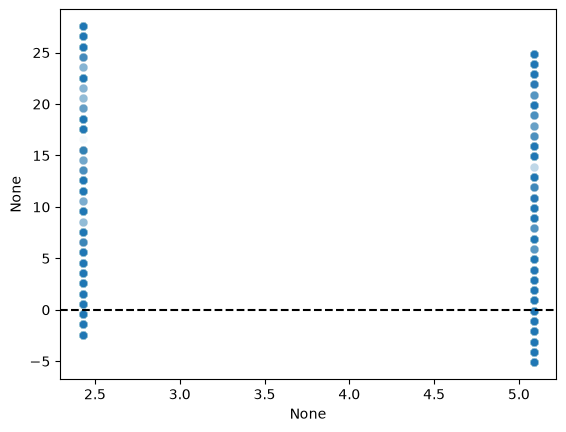

In [7]:
sns.scatterplot(x=model.fittedvalues, y=model.resid, alpha=0.05)
plt.axhline(0, color='black', linestyle='--')

When the predictor is binary, the fitted values are the two group means. {++No. The residuals are more spread out in the below \$35,000 group.++}